# Chapter 11 · Conditioning and conditional expectation: interactive demos

Companion to Chapter 11 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/11-conditional-expectation.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.conditional import (SUM_PAIRS, binned_conditional_mean, defining_property_mc, midpoints,
                                   partition_expectation, poisson_sum_conditional, sample_poisson_sum,
                                   sample_sum)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. Conditional expectation given a finite partition

Kolmogorov's definition (Definition 11.8) asks for a $\mathcal G$-measurable $\hat X$ with
$\int_A\hat X\,d\mathbb P=\int_AX\,d\mathbb P$ for every $A\in\mathcal G$. When $\mathcal G$ is generated by a partition of
$\Omega$ into cells of positive probability, $\mathcal G$-measurable means constant on each cell, and the second property
fixes the constant: it is the average of $X$ over the cell (Exercise 11.3). Here $\Omega=(0,1)$ with Lebesgue measure, and
$\mathcal G$ is generated by $k$ intervals, of equal length or with random endpoints. The shaded areas between $X$ and
$\mathbb E[X\mid\mathcal G]$ cancel on every cell. More cells mean more information: $\mathbb E[X\mid\mathcal G]$ follows $X$
more closely, and its variance grows towards that of $X$.

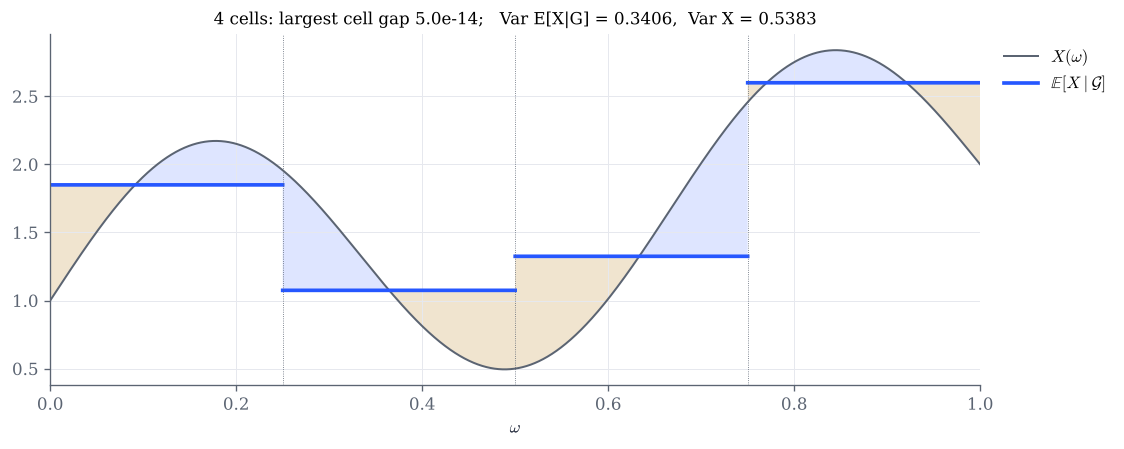

In [3]:
FUNCS = {
    "1 + sin(3 pi w) + w": lambda w: 1 + np.sin(3 * np.pi * w) + w,
    "w^2": lambda w: w ** 2,
    "indicator of (0.3, 0.55)": lambda w: ((w > 0.3) & (w < 0.55)).astype(float),
    "1 / sqrt(w), unbounded": lambda w: 1 / np.sqrt(w),
}

def partition_demo(X="1 + sin(3 pi w) + w", k=4, cells="equal", seed=0):
    n = 20_000
    w = midpoints(0, 1, n)
    p = np.full(n, 1 / n)                     # Lebesgue measure on a fine grid of (0, 1)
    x = FUNCS[X](w)
    if cells == "equal":
        cuts = np.linspace(0, 1, k + 1)
    else:
        cuts = np.concatenate([[0], np.sort(np.random.default_rng(seed).random(k - 1)), [1]])
    lab = np.searchsorted(cuts, w, side="right") - 1
    xhat = partition_expectation(x, p, lab)
    gaps = [abs(np.sum((x - xhat)[lab == j] * p[lab == j])) for j in range(k)]
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.fill_between(w, x, xhat, where=x >= xhat, color=COBALT, alpha=0.15, lw=0)
    ax.fill_between(w, x, xhat, where=x < xhat, color=GOLD, alpha=0.2, lw=0)
    ax.plot(w, x, color=GREY, lw=1.2, label=r"$X(\omega)$")
    for j in range(k):
        cell = lab == j
        ax.plot(w[cell], xhat[cell], color=COBALT, lw=2.2,
                label=r"$\mathbb{E}[X\mid\mathcal{G}]$" if j == 0 else None)
    for c in cuts[1:-1]:
        ax.axvline(c, color=GREY, lw=0.5, ls=":")
    ax.set(xlabel=r"$\omega$", xlim=(0, 1))
    if X.startswith("1 /"):
        ax.set_ylim(0, 6)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.set_title(f"{k} cells: largest cell gap {max(gaps):.1e};   "
                 f"Var E[X|G] = {np.var(xhat):.4f},  Var X = {np.var(x):.4f}")
    plt.show()

partition_demo()

In [4]:
# Explore: increase k, switch to random cells, try the unbounded X (it is integrable, so E[X|G] exists).
interact(partition_demo,
         X=Dropdown(options=list(FUNCS), value="1 + sin(3 pi w) + w", description="X"),
         k=IntSlider(value=4, min=1, max=40, continuous_update=False, description="cells k"),
         cells=Dropdown(options=["equal", "random"], value="equal", description="cells"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 2. A Poisson variable given the sum

Let $X\sim\mathcal P(\lambda)$ and $Y\sim\mathcal P(\mu)$ be independent and $Z=X+Y$. The worked exercise of Example 11.2
computes, from the joint density, $f_{X\mid Z=m}(k)=f_X(k)f_Y(m-k)/f_Z(m)$, and finds the binomial law
$B\big(m,\frac\lambda{\lambda+\mu}\big)$; hence $h(m)=\mathbb E[X\mid Z=m]=m\frac\lambda{\lambda+\mu}$. Left: the three versions
of the conditional law (definition, binomial formula, simulation). Right: $h$ against the averages of $X$ over the
simulated pairs with $Z=m$, with two standard errors.

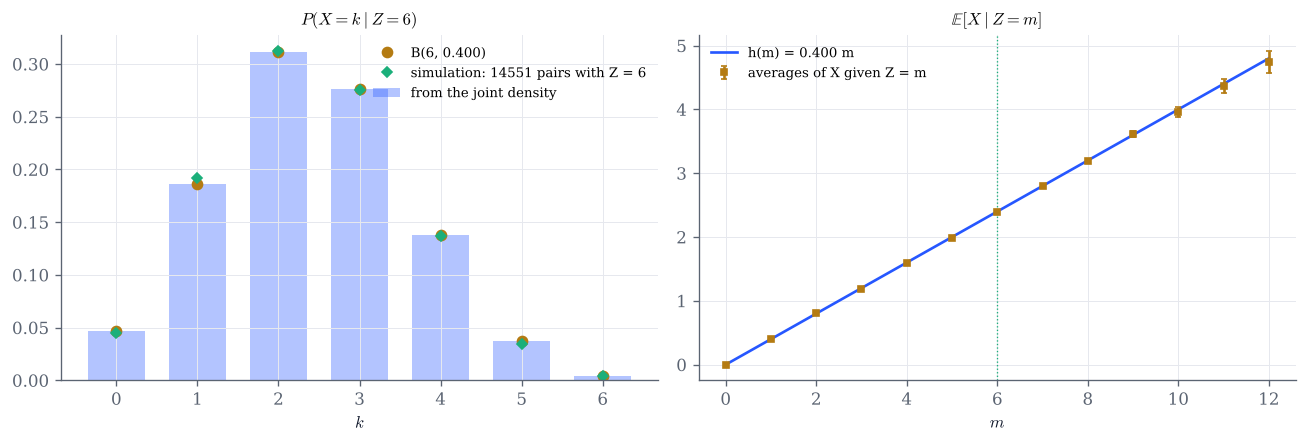

In [5]:
def poisson_demo(lam=2.0, mu=3.0, m=6, log10_n=5.0, seed=2026):
    n = int(10 ** log10_n)
    p = lam / (lam + mu)
    x, z = sample_poisson_sum(n, lam, mu, seed=seed)
    k = np.arange(m + 1)
    sel = x[z == m]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    a1.bar(k, poisson_sum_conditional(lam, mu, m), color=COBALT, alpha=0.35, width=0.7,
           label="from the joint density")
    a1.plot(k, stats.binom.pmf(k, m, p), "o", color=GOLD, label=f"B({m}, {p:.3f})")
    if sel.size:
        a1.plot(k, np.bincount(sel, minlength=m + 1)[: m + 1] / sel.size, "D", color=GREEN, ms=4,
                label=f"simulation: {sel.size} pairs with Z = {m}")
    a1.set(xlabel="$k$", title=f"$P(X=k\\mid Z={m})$")
    a1.legend(fontsize=8)
    ms = np.arange(0, int(np.quantile(z, 0.995)) + 1)
    cnt = np.array([(z == j).sum() for j in ms])
    keep = cnt > 1
    means = np.array([x[z == j].mean() for j in ms[keep]])
    ses = np.array([x[z == j].std(ddof=1) / np.sqrt(c) for j, c in zip(ms[keep], cnt[keep])])
    a2.plot(ms, p * ms, color=COBALT, label=f"h(m) = {p:.3f} m")
    a2.errorbar(ms[keep], means, yerr=2 * ses, fmt="s", color=GOLD, ms=3.5, capsize=2,
                label="averages of X given Z = m")
    a2.axvline(m, color=GREEN, lw=0.8, ls=":")
    a2.set(xlabel="$m$", title=r"$\mathbb{E}[X\mid Z=m]$")
    a2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

poisson_demo()

In [6]:
# Explore: the conditional law depends on lambda and mu only through lambda / (lambda + mu).
interact(poisson_demo,
         lam=FloatSlider(value=2.0, min=0.2, max=10.0, step=0.2, continuous_update=False, description="lambda"),
         mu=FloatSlider(value=3.0, min=0.2, max=10.0, step=0.2, continuous_update=False, description="mu"),
         m=IntSlider(value=6, min=0, max=25, continuous_update=False, description="m"),
         log10_n=FloatSlider(value=5.0, min=3.0, max=6.0, step=0.25, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 3. $\mathbb E[X\mid X+Y]$ by binning

When $\mathbb P(Z=z)=0$ we cannot condition on $\{Z=z\}$ by counting; we condition on $\{Z\in I\}$ for small bins $I$
instead (Remark 11.15). The average of $X$ over the pairs with $Z\in I$ is the cell average, that is,
$\mathbb E[X\mid\mathcal G]$ for the $\sigma$-algebra generated by the bins under the empirical measure. For independent
exponentials $\mathbb E[X\mid Z]=\frac Z2$ and $X\mid Z=z\sim U(0,z)$ (Example 11.14); by symmetry
$\mathbb E[X\mid Z]=\frac Z2$ for every i.i.d. pair (Exercise 11.4), and $\mathbb E[X\mid Z]=\frac23Z$ for $X\sim\Gamma(2,1)$,
$Y\sim\mathrm{Exp}(1)$ (Exercise 11.7). Left: samples, $h$ and the bin averages with two standard errors. Right: the values
of $X$ in the bin around $z_0$ (green band), against the exact conditional density at $z_0$. The table checks
property 2) of Definition 11.8 on three events $\{Z\in B\}$.

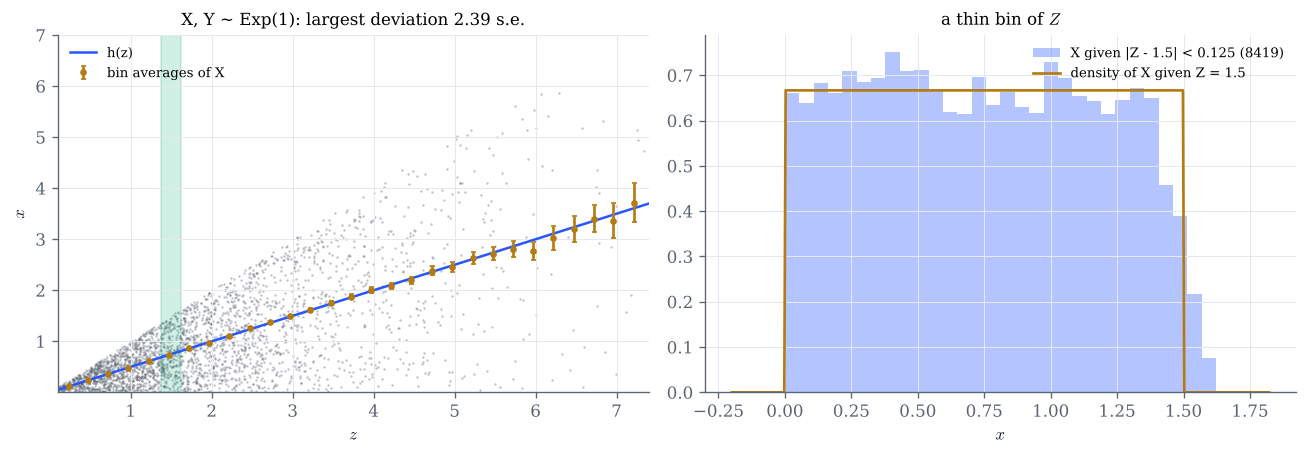

estimates of E[(X - g(Z)) 1{Z in B}] +- standard error
  B = (  -inf,   1.18]   g = h: +0.00013 +- 0.00040    g = 0.9 h: +0.01184 +- 0.00040
  B = (  1.18,   2.28]   g = h: -0.00064 +- 0.00090    g = 0.9 h: +0.02751 +- 0.00091
  B = (  2.28,    inf]   g = h: +0.00092 +- 0.00201    g = 0.9 h: +0.06055 +- 0.00203


In [7]:
COND = {      # density of X given Z = z for the pairs of SUM_PAIRS
    "exponential": lambda x, z: np.where((x > 0) & (x < z), 1 / z, 0.0),
    "uniform": lambda x, z: np.where((x > max(0, z - 1)) & (x < min(1, z)), 1 / (min(1, z) - max(0, z - 1)), 0.0),
    "normal": lambda x, z: stats.norm.pdf(x, z / 2, np.sqrt(0.5)),
    "gamma": lambda x, z: np.where((x > 0) & (x < z), 2 * x / z ** 2, 0.0),
}

def binning_demo(pair="exponential", log10_n=5.0, width=0.25, z0=1.5, seed=2026):
    n = int(10 ** log10_n)
    x, z = sample_sum(pair, n, seed)
    h = SUM_PAIRS[pair][1]
    lo, hi = np.quantile(z, [0.005, 0.995])
    edges = np.arange(lo, hi + width, width)
    b = binned_conditional_mean(z, x, edges)
    dev = np.nanmax(np.abs(b.mean_x - h(b.mean_z)) / b.se_x)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9))
    m = min(n, 3000)
    a1.scatter(z[:m], x[:m], s=2, color=GREY, alpha=0.4, lw=0)
    t = np.linspace(lo, hi, 100)
    a1.plot(t, h(t), color=COBALT, lw=1.5, label="h(z)")
    a1.errorbar(b.mean_z, b.mean_x, yerr=2 * b.se_x, fmt="o", color=GOLD, ms=3, capsize=1.5,
                label="bin averages of X")
    a1.axvspan(z0 - width / 2, z0 + width / 2, color=GREEN, alpha=0.2)
    a1.set(xlim=(lo, hi), ylim=tuple(np.quantile(x, [0.001, 0.999])), xlabel="$z$", ylabel="$x$",
           title=f"{SUM_PAIRS[pair][0]}: largest deviation {dev:.2f} s.e.")
    a1.legend(fontsize=8, loc="upper left")
    sel = x[np.abs(z - z0) < width / 2]
    if sel.size > 1:
        a2.hist(sel, bins=30, density=True, color=COBALT, alpha=0.35,
                label=f"X given |Z - {z0:g}| < {width / 2:g} ({sel.size})")
        xs = np.linspace(sel.min() - 0.2, sel.max() + 0.2, 400)
        a2.plot(xs, COND[pair](xs, z0), color=GOLD, lw=1.6, label=f"density of X given Z = {z0:g}")
        a2.legend(fontsize=8)
    a2.set(xlabel="$x$", title="a thin bin of $Z$")
    fig.tight_layout()
    plt.show()
    q1, q2 = np.quantile(z, [1 / 3, 2 / 3])
    sets = [(-np.inf, q1), (q1, q2), (q2, np.inf)]
    r_good = defining_property_mc(x, h(z), z, sets)
    r_bad = defining_property_mc(x, 0.9 * h(z), z, sets)
    print("estimates of E[(X - g(Z)) 1{Z in B}] +- standard error")
    for (a, c), g1, s1, g2, s2 in zip(sets, r_good.mean, r_good.se, r_bad.mean, r_bad.se):
        print(f"  B = ({a:6.2f}, {c:6.2f}]   g = h: {g1:+.5f} +- {s1:.5f}    g = 0.9 h: {g2:+.5f} +- {s2:.5f}")

binning_demo()

In [8]:
# Explore: narrow bins are closer to {Z = z} but noisier; wide bins are smooth but biased where h is curved
# or where the density of Z is steep (Exercise 11.7).
interact(binning_demo,
         pair=Dropdown(options=list(SUM_PAIRS), value="exponential", description="pair"),
         log10_n=FloatSlider(value=5.0, min=3.0, max=6.5, step=0.25, continuous_update=False, description="log10 n"),
         width=FloatSlider(value=0.25, min=0.02, max=1.0, step=0.01, continuous_update=False, description="bin width"),
         z0=FloatSlider(value=1.5, min=-2.0, max=6.0, step=0.1, continuous_update=False, description="z0"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, take $X=\mathbf 1_{(0.3,0.55)}$ and $k=4$: what is $\mathbb E[X\mid\mathcal G]$ on the cell $[0.25,0.5)$, and why? This is a conditional probability $\mathbb P(A\mid\mathcal G)$.
- In section 1, compare the variances for $k=1,2,4,8$. Why can the variance only grow when every cell is split in two?
- In section 2, keep $\lambda/(\lambda+\mu)$ fixed and change $\lambda$: what changes on the left, and what on the right?
- In section 3, for `exponential`, take a bin width of $1$ and look at the first bins: the averages lie above $h$ at the bin centres but on $h$ at the bin means of $Z$. Why (Exercise 11.7 (a))?
- In section 3, for `normal`, the conditional density at $z_0$ is $\mathcal N(\frac{z_0}2,\frac12)$: check that its variance does not depend on $z_0$, unlike the other pairs.